# IADS5 · TP integrador — Ortelana Textil
### Actividad 10 · Regularización y GridSearchCV

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 10 · Regularización y GridSearchCV

**Qué se espera:** En la tarea de regresión compará LinearRegression, Ridge, Lasso y ElasticNet (alpha=1.0). Usá GridSearchCV con 5 folds para Ridge y Lasso, alpha en [0.01, 0.1, 1, 10, 100]. Graficá el camino de coeficientes de Lasso en escala logarítmica.

**Evidencia a entregar:** Tabla RMSE/R², mejores alphas, coeficientes y gráfico.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")
# Target de regresión: volumen anual = suma de los metros con dato de cada fila (comparable entre formatos)
df["volumen_anual_metros"] = df[[f"Metros{i}" for i in range(1, 13)]].sum(axis=1, min_count=1)

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

# Regresión de volumen_anual_metros (suma anual de los metros con dato): mismas filas de train y test
features_reg = ["Sucursal_ID", "Tela_ID", "Año"]
Xr_train, Xr_test = train[features_reg], test[features_reg]
yr_train, yr_test = train["volumen_anual_metros"], test["volumen_anual_metros"]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

def crear_pipeline(modelo):
    """Numéricas: imputar y escalar (la penalización depende de la escala).
    Categóricas: imputar y k-1 dummies (drop="first"); la categoría omitida es la referencia."""
    preprocesador = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), ["Año"]),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]),
         ["Sucursal_ID", "Tela_ID"]),
    ], verbose_feature_names_out=False)
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])

kf5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [3]:
# 10.1 LinearRegression, Ridge, Lasso y ElasticNet con alpha=1.0 (CV de 5 folds en train + test)
modelos = {
    "LinearRegression": LinearRegression(),
    "Ridge (alpha=1)": Ridge(alpha=1.0),
    "Lasso (alpha=1)": Lasso(alpha=1.0, max_iter=50000),
    "ElasticNet (alpha=1, l1_ratio=0.5)": ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=50000),
}

pipelines = {}
filas = []
for nombre, modelo in modelos.items():
    pipe = crear_pipeline(modelo)
    cv = cross_validate(pipe, Xr_train, yr_train, cv=kf5, scoring=["neg_root_mean_squared_error", "r2"], n_jobs=-1)
    pipe.fit(Xr_train, yr_train)
    pipelines[nombre] = pipe
    pred = pipe.predict(Xr_test)
    filas.append({"Modelo": nombre,
                  "RMSE CV": -cv["test_neg_root_mean_squared_error"].mean(),
                  "RMSE CV desvío": cv["test_neg_root_mean_squared_error"].std(),
                  "R2 CV": cv["test_r2"].mean(),
                  "RMSE test": np.sqrt(mean_squared_error(yr_test, pred)),
                  "R2 test": r2_score(yr_test, pred),
                  "MAE test": mean_absolute_error(yr_test, pred)})
tabla_reg = pd.DataFrame(filas).set_index("Modelo")
tabla_reg.round(4)

,RMSE CV,RMSE CV desvío,R2 CV,RMSE test,R2 test,MAE test
Modelo,,,,,,
LinearRegression,1311.3421,90.4017,0.6778,1272.3121,0.7021,843.4493
Ridge (alpha=1),1316.9013,98.6990,0.6759,1279.4564,0.6988,836.1548
Lasso (alpha=1),1316.9135,99.6307,0.6758,1282.9373,0.6971,838.2932
"ElasticNet (alpha=1, l1_ratio=0.5)",2217.0132,183.3727,0.0870,2216.2632,0.0961,1573.5431


In [4]:
# 10.2 GridSearchCV (5 folds, solo train) para Ridge y Lasso con alpha en [0.01, 0.1, 1, 10, 100]
grilla = {"modelo__alpha": [0.01, 0.1, 1, 10, 100]}
busquedas = {}

for nombre, modelo in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=50000))]:
    busqueda = GridSearchCV(crear_pipeline(modelo), grilla, cv=kf5, scoring="neg_root_mean_squared_error", n_jobs=-1)
    busqueda.fit(Xr_train, yr_train)
    busquedas[nombre] = busqueda

    mejor_alpha = busqueda.best_params_["modelo__alpha"]
    print(f"{nombre}: mejor alpha = {mejor_alpha} | RMSE CV = {-busqueda.best_score_:.2f} m")
    display(pd.DataFrame({"RMSE CV": -busqueda.cv_results_["mean_test_score"],
                          "desvío": busqueda.cv_results_["std_test_score"]},
                         index=pd.Index(grilla["modelo__alpha"], name="alpha")).T.round(4))

    pred = busqueda.predict(Xr_test)
    tabla_reg.loc[f"{nombre} (GridSearch, alpha={mejor_alpha})"] = {
        "RMSE CV": -busqueda.best_score_,
        "RMSE CV desvío": busqueda.cv_results_["std_test_score"][busqueda.best_index_],
        "R2 CV": np.nan,
        "RMSE test": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2 test": r2_score(yr_test, pred),
        "MAE test": mean_absolute_error(yr_test, pred)}

tabla_reg.round(4)

Ridge: mejor alpha = 0.1 | RMSE CV = 1311.27 m


alpha,0.01,0.10,1.00,10.00,100.00
RMSE CV,1311.323,1311.2654,1316.9013,1417.1999,1826.3339
desvío,90.518,91.5201,98.6990,126.2934,169.6227


Lasso: mejor alpha = 0.01 | RMSE CV = 1311.34 m


alpha,0.01,0.10,1.00,10.00,100.00
RMSE CV,1311.3378,1311.3863,1316.9135,1442.1381,2248.9304
desvío,90.5058,91.4408,99.6307,126.2395,189.9632


,RMSE CV,RMSE CV desvío,R2 CV,RMSE test,R2 test,MAE test
Modelo,,,,,,
LinearRegression,1311.3421,90.4017,0.6778,1272.3121,0.7021,843.4493
Ridge (alpha=1),1316.9013,98.6990,0.6759,1279.4564,0.6988,836.1548
Lasso (alpha=1),1316.9135,99.6307,0.6758,1282.9373,0.6971,838.2932
"ElasticNet (alpha=1, l1_ratio=0.5)",2217.0132,183.3727,0.0870,2216.2632,0.0961,1573.5431
"Ridge (GridSearch, alpha=0.1)",1311.2654,91.5201,NaN,1272.6743,0.7019,842.3271
"Lasso (GridSearch, alpha=0.01)",1311.3378,90.5058,NaN,1272.3564,0.7021,843.3515


In [5]:
# 10.3 Coeficientes y cantidad de coeficientes anulados
nombres = pipelines["LinearRegression"].named_steps["preprocesamiento"].get_feature_names_out()

coeficientes = pd.DataFrame({
    "LinearRegression": pipelines["LinearRegression"].named_steps["modelo"].coef_,
    "Ridge (mejor alpha)": busquedas["Ridge"].best_estimator_.named_steps["modelo"].coef_,
    "Lasso (mejor alpha)": busquedas["Lasso"].best_estimator_.named_steps["modelo"].coef_,
    "Lasso (alpha=1)": pipelines["Lasso (alpha=1)"].named_steps["modelo"].coef_,
    "ElasticNet (alpha=1)": pipelines["ElasticNet (alpha=1, l1_ratio=0.5)"].named_steps["modelo"].coef_,
}, index=nombres)

print(f"Coeficiente de la variable numérica (de {len(nombres)} en total):")
display(coeficientes.loc[["Año"]].round(4))
display(pd.DataFrame({"coeficientes = 0": (coeficientes == 0).sum(),
                      "suma |coef|": coeficientes.abs().sum()}).T.round(4))

Coeficiente de la variable numérica (de 41 en total):


,LinearRegression,Ridge (mejor alpha),Lasso (mejor alpha),Lasso (alpha=1),ElasticNet (alpha=1)
Año,-236.1954,-236.1708,-236.1845,-235.0505,-151.8049


,LinearRegression,Ridge (mejor alpha),Lasso (mejor alpha),Lasso (alpha=1),ElasticNet (alpha=1)
coeficientes = 0,0.0000,0.0000,0.000,0.0000,1.0000
suma |coef|,107437.5293,105292.6035,107196.207,87870.1056,3474.3713


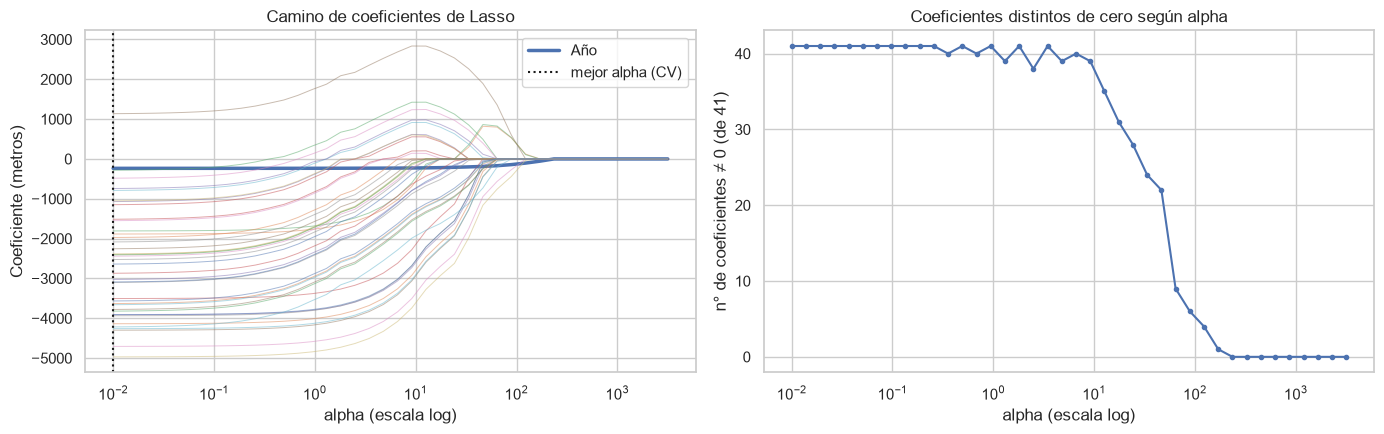

In [6]:
# 10.4 Camino de coeficientes de Lasso (alpha en escala logarítmica)
alphas = np.logspace(-2, 3.5, 40)
camino = []
for alpha in alphas:
    lasso = crear_pipeline(Lasso(alpha=alpha, max_iter=50000)).fit(Xr_train, yr_train)
    camino.append(lasso.named_steps["modelo"].coef_)
camino = pd.DataFrame(camino, index=alphas, columns=nombres)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for col in camino.columns:
    if col == "Año":
        axes[0].plot(alphas, camino[col], lw=2.5, label=col)       # numérica resaltada
    else:
        axes[0].plot(alphas, camino[col], lw=0.7, alpha=0.5)       # dummies de sucursal y tela
axes[0].axvline(busquedas["Lasso"].best_params_["modelo__alpha"], color="k", ls=":", label="mejor alpha (CV)")
axes[0].set_xscale("log")
axes[0].set(title="Camino de coeficientes de Lasso", xlabel="alpha (escala log)", ylabel="Coeficiente (metros)")
axes[0].legend()

axes[1].plot(alphas, (camino != 0).sum(axis=1), "o-", ms=3)
axes[1].set_xscale("log")
axes[1].set(title="Coeficientes distintos de cero según alpha", xlabel="alpha (escala log)",
            ylabel=f"n° de coeficientes ≠ 0 (de {camino.shape[1]})")
plt.tight_layout()
plt.show()

In [7]:
# 10.5 Modelo de regresión elegido: Ridge con alpha=1
# Mismo error que LinearRegression, pero con coeficientes más estables (las 41 dummies comparten información)
ridge_final = pipelines["Ridge (alpha=1)"]
print("Coeficientes de Ridge (alpha=1) con mayor magnitud:")
display(pd.Series(ridge_final.named_steps["modelo"].coef_, index=nombres)
        .sort_values(key=abs, ascending=False).head(10).round(2).rename("coeficiente (metros)").to_frame())
tabla_reg.loc[["LinearRegression", "Ridge (alpha=1)"]].round(4)

Coeficientes de Ridge (alpha=1) con mayor magnitud:


,coeficiente (metros)
Sucursal_ID_9,-4781.62
Sucursal_ID_7,-4525.36
Sucursal_ID_6,-4113.88
Sucursal_ID_10,-4075.23
Sucursal_ID_12,-3956.87
Sucursal_ID_8,-3749.58
Sucursal_ID_5,-3738.94
Sucursal_ID_11,-3725.43
Tela_ID_TELA-019,-3653.23
Sucursal_ID_4,-3326.01


,RMSE CV,RMSE CV desvío,R2 CV,RMSE test,R2 test,MAE test
Modelo,,,,,,
LinearRegression,1311.3421,90.4017,0.6778,1272.3121,0.7021,843.4493
Ridge (alpha=1),1316.9013,98.6990,0.6759,1279.4564,0.6988,836.1548


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Tarea:** regresión de `volumen_anual_metros` (suma anual de los metros con dato), con `Sucursal_ID`, `Tela_ID` y `Año`. Usamos el volumen anual y no `Metros2` porque `Metros2` mide períodos distintos según el formato (un mes en M, un semestre en S y C) y no es comparable entre filas.
- **Preprocesamiento:** el de la Actividad 09 dentro del pipeline (imputación + escalado de `Año`, imputación + one-hot de sucursal y tela). Acá el escalado sí es imprescindible, porque la penalización actúa sobre la magnitud de los coeficientes (Unidad 5: "escalado obligatorio").
- **Codificación con k−1 dummies:** como indica la teoría (Unidades 2 y 5), en los modelos lineales cada variable categórica con k niveles se codifica con k−1 dummies (`drop='first'`). La categoría omitida queda como referencia y se evita la colinealidad perfecta entre las dummies y el intercepto (la "trampa de las dummies"). Quedan 41 coeficientes: 1 numérico, 11 de sucursal y 29 de tela.
- **Modelos:** `LinearRegression`, `Ridge`, `Lasso` y `ElasticNet` (l1_ratio 0,5), todos con alpha = 1.
- **Evaluación:** KFold de 5 folds sobre train (RMSE y R²) y luego test.
- **GridSearchCV:** 5 folds solo en train, con alpha ∈ {0,01, 0,1, 1, 10, 100} para Ridge y Lasso, optimizando RMSE.
- **Camino de Lasso:** 40 valores de alpha entre 10⁻² y ~3·10³ en escala logarítmica.

**Interpretación de los resultados:**
- **Lineal, Ridge(1) y Lasso(1):** son prácticamente iguales, con RMSE CV ≈ 1.311–1.317 m (±90–100) y en test ≈ 1.272–1.283 m (R² ≈ 0,70).
- **ElasticNet(1):** empeora mucho (RMSE CV 2.217 m, R² en test 0,10). Con alpha = 1, su mezcla L1+L2 encoge demasiado los coeficientes (suma |coef| de 3.474 contra 107.438 de la lineal): es underfitting.
- **Mejores alphas por CV:** Ridge alpha = 0,1 (1.311,3 m) y Lasso alpha = 0,01 (1.311,3 m). Con alpha = 100 empeoran mucho (1.826 y 2.249 m).
- **Regla de 1 error estándar (Unidad 5):** el SE de la CV es ≈ desvío/√5 ≈ 41 m. Ridge con alpha = 1 (1.316,9 m) está a solo 5,6 m del mejor, dentro de 1 SE, y es el modelo más regularizado que cumple esa condición (alpha = 10 ya sube a 1.417 m).
- **Coeficientes:** `Año` aporta ~−236 m por desvío en todos los modelos. Los coeficientes más grandes son las dummies de sucursal (hasta −4.782 m respecto de la sucursal 1) y algunas telas.

**Modelo de regresión elegido: `Ridge(alpha=1)`.**
- Su error es equivalente al de `LinearRegression` (RMSE CV 1.317 contra 1.311 m, una diferencia de 0,4% y muy inferior a 1 SE).
- Con 41 dummies, la penalización L2 estabiliza los coeficientes de las sucursales y telas con pocos registros: la suma |coef| baja respecto de la lineal sin perder error.
- Es la elección de la regla de 1 SE: el modelo más simple (más regularizado) cuyo error no se distingue del mejor.
- No elegimos por el RMSE de test (donde la lineal da 1.272 m contra 1.279 m), porque el test no se usa para seleccionar.

**Pregunta de análisis:** ¿Qué diferencia hay entre L1 y L2? ¿Lasso anuló coeficientes? ¿Qué cambia al crecer alpha?
- **L1 contra L2:**
  - L2 (Ridge) suma a la pérdida α·Σβ²: encoge todos los coeficientes de forma proporcional, pero nunca los lleva exactamente a 0.
  - L1 (Lasso) suma α·Σ|β|: la geometría de la penalización produce soluciones con coeficientes exactamente en 0, es decir, selecciona variables.
- **¿Lasso anuló coeficientes?** Con alpha ≤ 1, no: ninguna sucursal ni tela es irrelevante para el volumen anual. Solo ElasticNet(1) anuló 1. En el camino de Lasso se ve que empieza a anular coeficientes con alpha mayores.
- **Qué cambia al crecer alpha:** en el camino de Lasso, los coeficientes se encogen y van cayendo a 0 a medida que crece alpha, empezando por las dummies de menor aporte, hasta que no queda ninguno y el modelo predice la media.
  - Más alpha significa menos varianza pero más sesgo.
  - Pasado el óptimo (alpha 0,01–1), el error sube.

**Limitaciones o mejoras posibles:**
- La regularización casi no cambia el error porque hay muchas filas por coeficiente (2.628 contra 41): no hay un sobreajuste fuerte que corregir.
- El modelo lineal es aditivo y no captura la interacción sucursal × tela. El árbol regresor sin límite de profundidad de la Actividad 05 baja el RMSE de test a 964 m justamente por eso, aunque lo hace memorizando el volumen de cada par.
- La CV aleatoria comparte pares (sucursal, tela) entre train y validación. Para una sucursal o tela nueva, el modelo solo puede usar el efecto promedio de la otra variable.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]